# 🚀 06. Non-Parametric k-NN & Ensemble Boosting (AdaBoost & Gradient Boosting)

**Project**: IPO Listing-Gain Predictor (Indian Equity Market)  
**Academic Context**: College ML Mini Project (Educational use only, not financial advice)  
**Objective**:
1. **k-Nearest Neighbors (k-NN)**:
   - Tune $K \in [1, 20]$ for both Regression (`listing_gain_pct`) and Classification (`positive_listing`).
   - Plot Accuracy and MSE curves vs $K$, pick the optimal $K$, and analyze the locality-smoothing tradeoff.
   - Implement and test **Peer IPO Similarity Search** (`src/similar_ipos.py`) with strict anti-leakage temporal filtering.
2. **Ensemble Boosting**:
   - **AdaBoost**: Decision stumps (`estimator=DecisionTreeClassifier(max_depth=1)`) and tree regressors.
   - **Gradient Boosting**: `GradientBoostingRegressor` and `GradientBoostingClassifier` tuned using `GridSearchCV` with `TimeSeriesSplit`.
   - Plot comparative **Feature Importances** across the boosting models.
3. **Model & Metrics Persistence**:
   - Append all computed metrics to `reports/metrics.csv`.
   - Persist all trained models in `models/` with `joblib`.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.ensemble import (
    AdaBoostClassifier, AdaBoostRegressor,
    GradientBoostingRegressor, GradientBoostingClassifier
)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)

# Add project root to sys.path
sys.path.insert(0, os.path.abspath(".."))
from src.similar_ipos import IPOSimilarityFinder, get_similar_ipos

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

FIG_DIR = os.path.join("..", "reports", "figures")
REPORTS_DIR = os.path.join("..", "reports")
MODELS_DIR = os.path.join("..", "models")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

new_metrics = []
print("Environment and modules successfully initialized.")

Environment and modules successfully initialized.


## 1. Load Preprocessed Datasets & Targets

We load `train_preprocessed.csv` and `test_preprocessed.csv` along with our unscaled clustered reference tables.

In [2]:
DATA_DIR = os.path.join("..", "data", "processed")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join("data", "processed")

train_df = pd.read_csv(os.path.join(DATA_DIR, "train_preprocessed.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test_preprocessed.csv"))

NON_FEATURE_COLS = [
    'ipo_name', 'listing_date', 'listing_price', 'listing_gain_pct',
    'positive_listing', 'verdict', 'market_mood', 'cluster_id'
]
feature_cols = [c for c in train_df.columns if c not in NON_FEATURE_COLS]

X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

# Targets
y_train_gain = train_df['listing_gain_pct'].values
y_test_gain = test_df['listing_gain_pct'].values

y_train_pos = train_df['positive_listing'].values
y_test_pos = test_df['positive_listing'].values

print(f"Feature count : {len(feature_cols)}")
print(f"Train samples : {len(X_train)}")
print(f"Test samples  : {len(X_test)}")

Feature count : 30
Train samples : 225
Test samples  : 75


## 2. k-Nearest Neighbors (k-NN) Evaluation ($K = 1 \dots 20$)

We evaluate both regression and classification performance across neighborhood sizes $K \in [1, 20]$:
- **Regression**: Predicts expected `listing_gain_pct` as local weighted/uniform average of $K$ nearest neighbors.
- **Classification**: Predicts `positive_listing` (1 vs 0) via majority voting.
- **Bias-Variance Dynamics**:
  - $K=1$: Overfits to training data (Train error $= 0$, high variance on test).
  - Higher $K$: Smoother decision surface (lower variance, higher bias).

Optimal K for Regression     : K = 9 (Test MSE: 118.10, RMSE: 10.87)
Optimal K for Classification : K = 5 (Test Accuracy: 92.0%)


Saved figure -> ..\reports\figures\16_knn_k_tuning.png


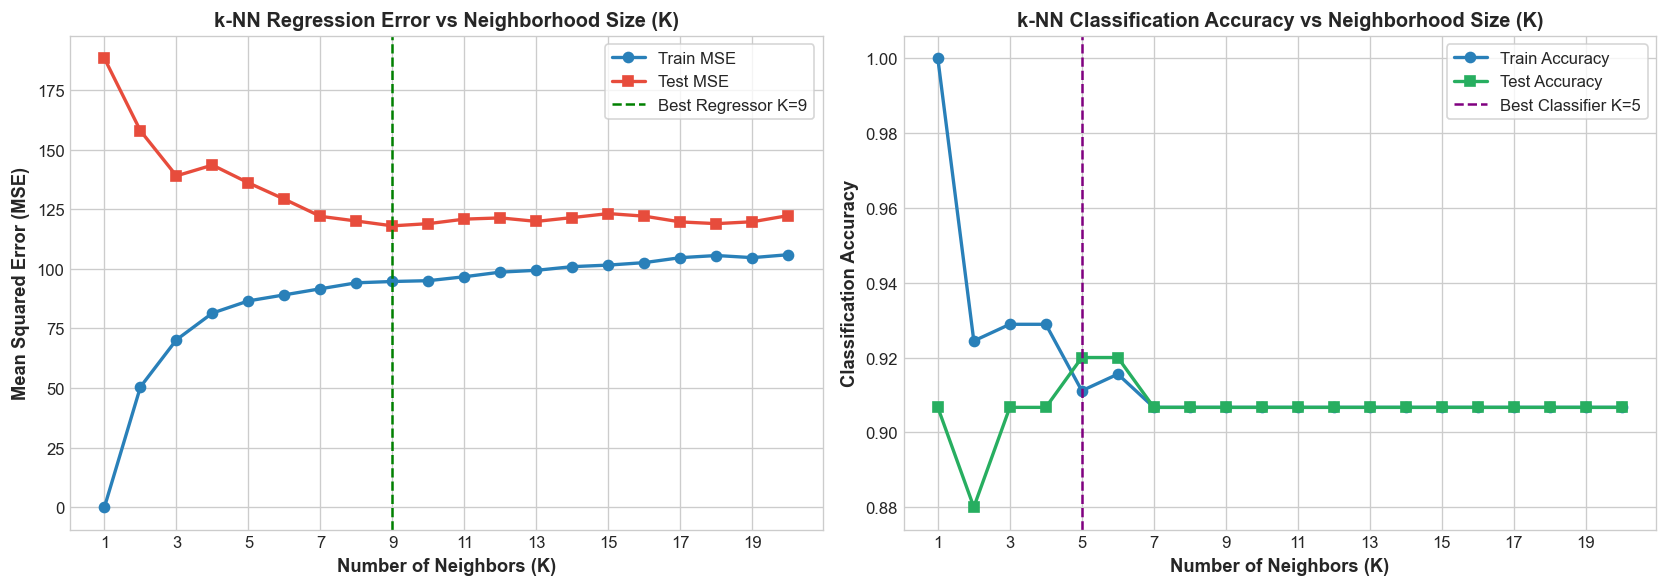

In [3]:
k_values = list(range(1, 21))

knn_reg_train_mse = []
knn_reg_test_mse = []

knn_clf_train_acc = []
knn_clf_test_acc = []

for k in k_values:
    # 1. Regression
    reg = KNeighborsRegressor(n_neighbors=k)
    reg.fit(X_train, y_train_gain)
    knn_reg_train_mse.append(mean_squared_error(y_train_gain, reg.predict(X_train)))
    knn_reg_test_mse.append(mean_squared_error(y_test_gain, reg.predict(X_test)))
    
    # 2. Classification
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train_pos)
    knn_clf_train_acc.append(accuracy_score(y_train_pos, clf.predict(X_train)))
    knn_clf_test_acc.append(accuracy_score(y_test_pos, clf.predict(X_test)))

# Select best K
best_k_reg = k_values[int(np.argmin(knn_reg_test_mse))]
best_k_clf = k_values[int(np.argmax(knn_clf_test_acc))]

print(f"Optimal K for Regression     : K = {best_k_reg} (Test MSE: {knn_reg_test_mse[best_k_reg-1]:.2f}, RMSE: {np.sqrt(knn_reg_test_mse[best_k_reg-1]):.2f})")
print(f"Optimal K for Classification : K = {best_k_clf} (Test Accuracy: {knn_clf_test_acc[best_k_clf-1]:.1%})")

# Dual-panel diagnostic figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Regression MSE vs K
axes[0].plot(k_values, knn_reg_train_mse, marker='o', color='#2980b9', lw=2, label='Train MSE')
axes[0].plot(k_values, knn_reg_test_mse, marker='s', color='#e74c3c', lw=2, label='Test MSE')
axes[0].axvline(best_k_reg, color='green', linestyle='--', label=f'Best Regressor K={best_k_reg}')
axes[0].set_title("k-NN Regression Error vs Neighborhood Size (K)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Number of Neighbors (K)", fontsize=11, fontweight='semibold')
axes[0].set_ylabel("Mean Squared Error (MSE)", fontsize=11, fontweight='semibold')
axes[0].set_xticks(range(1, 21, 2))
axes[0].legend(frameon=True)

# Subplot 2: Classification Accuracy vs K
axes[1].plot(k_values, knn_clf_train_acc, marker='o', color='#2980b9', lw=2, label='Train Accuracy')
axes[1].plot(k_values, knn_clf_test_acc, marker='s', color='#27ae60', lw=2, label='Test Accuracy')
axes[1].axvline(best_k_clf, color='purple', linestyle='--', label=f'Best Classifier K={best_k_clf}')
axes[1].set_title("k-NN Classification Accuracy vs Neighborhood Size (K)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Neighbors (K)", fontsize=11, fontweight='semibold')
axes[1].set_ylabel("Classification Accuracy", fontsize=11, fontweight='semibold')
axes[1].set_xticks(range(1, 21, 2))
axes[1].legend(frameon=True)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "16_knn_k_tuning.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

# Retrain and save best k-NN models
best_knn_reg = KNeighborsRegressor(n_neighbors=best_k_reg).fit(X_train, y_train_gain)
best_knn_clf = KNeighborsClassifier(n_neighbors=best_k_clf).fit(X_train, y_train_pos)

joblib.dump(best_knn_reg, os.path.join(MODELS_DIR, "knn_regressor.joblib"))
joblib.dump(best_knn_clf, os.path.join(MODELS_DIR, "knn_classifier.joblib"))

# Record metrics
new_metrics.extend([
    {'model': 'kNN_Regressor', 'task': 'Regression', 'split': 'Train', 'metric': 'MSE', 'value': round(knn_reg_train_mse[best_k_reg-1], 4)},
    {'model': 'kNN_Regressor', 'task': 'Regression', 'split': 'Test', 'metric': 'MSE', 'value': round(knn_reg_test_mse[best_k_reg-1], 4)},
    {'model': 'kNN_Regressor', 'task': 'Regression', 'split': 'Test', 'metric': 'RMSE', 'value': round(np.sqrt(knn_reg_test_mse[best_k_reg-1]), 4)},
    {'model': 'kNN_Regressor', 'task': 'Regression', 'split': 'Test', 'metric': 'R2', 'value': round(r2_score(y_test_gain, best_knn_reg.predict(X_test)), 4)},
    {'model': 'kNN_Classifier', 'task': 'Classification', 'split': 'Train', 'metric': 'Accuracy', 'value': round(knn_clf_train_acc[best_k_clf-1], 4)},
    {'model': 'kNN_Classifier', 'task': 'Classification', 'split': 'Test', 'metric': 'Accuracy', 'value': round(knn_clf_test_acc[best_k_clf-1], 4)},
    {'model': 'kNN_Classifier', 'task': 'Classification', 'split': 'Test', 'metric': 'F1', 'value': round(f1_score(y_test_pos, best_knn_clf.predict(X_test), zero_division=0), 4)}
])

## 3. Peer IPO Similarity Search (`src/similar_ipos.py`)

In institutional IPO research, investors evaluate an upcoming issue against its **5 most similar historical predecessors**.
We instantiate `IPOSimilarityFinder` on the training data and demonstrate retrieval for a sample test IPO.

In [4]:
# Load training clustered dataset for rich metadata
train_clustered = pd.read_csv(os.path.join(DATA_DIR, "train_clustered.csv"))

# Initialize IPOSimilarityFinder
similarity_finder = IPOSimilarityFinder(
    historical_df=train_clustered,
    feature_matrix=train_df,
    feature_cols=feature_cols
)

# Persist similarity engine
similarity_finder.save(os.path.join(MODELS_DIR, "knn_similarity.joblib"))

# Test query with a sample test IPO
sample_test_ipo = test_df.iloc[10]
sample_test_name = sample_test_ipo['ipo_name']
sample_test_vec = test_df[feature_cols].iloc[10].values

print(f"Sample Query IPO (from Test Set): '{sample_test_name}'")
print(f"Listing Date: {sample_test_ipo['listing_date']} | Actual Listing Gain: {sample_test_ipo['listing_gain_pct']:.2f}%")

similar_peers = similarity_finder.find_similar_ipos(query=sample_test_vec, top_n=5)

print("\n" + "=" * 80)
print(f"TOP 5 MOST SIMILAR HISTORICAL PEER IPOs FOR '{sample_test_name}'")
print("=" * 80)
display(similar_peers)
print("=" * 80)

[SAVE] Similarity engine saved to: ..\models\knn_similarity.joblib
Sample Query IPO (from Test Set): 'Solaris Agro Industries Ltd'
Listing Date: 2024-03-03 | Actual Listing Gain: 21.33%

TOP 5 MOST SIMILAR HISTORICAL PEER IPOs FOR 'Solaris Agro Industries Ltd'


,ipo_name,sector,total_sub,listing_gain_pct,listing_date,similarity_score
0,Quantum Consumer Care Ltd,Manufacturing,44.07,14.12,2022-04-12,0.2238
1,Adani Renewable Power Ltd,Chemicals,31.90,-5.81,2021-02-19,0.2190
2,Indus Digital Networks Ltd,Financial Services,41.54,-4.48,2021-06-20,0.2079
3,Synergy Logistics Ltd,Healthcare,40.43,19.21,2021-09-25,0.1984
4,Tata Pharma Ltd,Chemicals,40.10,32.88,2022-07-30,0.1970


## 4. AdaBoost (Adaptive Boosting)

AdaBoost sequentially fits weak learners on weighted versions of the training data.
- **Classifier**: `DecisionTreeClassifier(max_depth=1)` decision stumps.
- **Note**: Configured using Scikit-Learn's modern `estimator` parameter (replacing deprecated `base_estimator`).

In [5]:
# 1. AdaBoost Classifier (positive_listing)
stump = DecisionTreeClassifier(max_depth=1, random_state=42)
ada_clf = AdaBoostClassifier(
    estimator=stump,
    n_estimators=100,
    learning_rate=0.08,
    random_state=42
)

# TimeSeriesSplit Cross-Validation
tscv = TimeSeriesSplit(n_splits=3)
ada_cv_scores = []
for tr_idx, val_idx in tscv.split(X_train):
    ada_clf.fit(X_train.iloc[tr_idx], y_train_pos[tr_idx])
    ada_cv_scores.append(accuracy_score(y_train_pos[val_idx], ada_clf.predict(X_train.iloc[val_idx])))

# Final fit on full training set
ada_clf.fit(X_train, y_train_pos)

y_tr_pred_ada = ada_clf.predict(X_train)
y_te_pred_ada = ada_clf.predict(X_test)
y_te_prob_ada = ada_clf.predict_proba(X_test)[:, 1]

ada_acc_tr = accuracy_score(y_train_pos, y_tr_pred_ada)
ada_acc_te = accuracy_score(y_test_pos, y_te_pred_ada)
ada_f1_te = f1_score(y_test_pos, y_te_pred_ada, zero_division=0)
ada_auc_te = roc_auc_score(y_test_pos, y_te_prob_ada)

print("=" * 65)
print("ADABOOST CLASSIFIER EVALUATION")
print("=" * 65)
print(f"TimeSeries CV Mean Accuracy : {np.mean(ada_cv_scores):.4f}")
print(f"Train Accuracy              : {ada_acc_tr:.4f}")
print(f"Test Accuracy               : {ada_acc_te:.4f}")
print(f"Test F1-Score               : {ada_f1_te:.4f}")
print(f"Test ROC-AUC                : {ada_auc_te:.4f}")
print("=" * 65)

# Save AdaBoost model
joblib.dump(ada_clf, os.path.join(MODELS_DIR, "adaboost_classifier.joblib"))

new_metrics.extend([
    {'model': 'AdaBoost_Classifier', 'task': 'Classification', 'split': 'Train', 'metric': 'Accuracy', 'value': round(ada_acc_tr, 4)},
    {'model': 'AdaBoost_Classifier', 'task': 'Classification', 'split': 'Test', 'metric': 'Accuracy', 'value': round(ada_acc_te, 4)},
    {'model': 'AdaBoost_Classifier', 'task': 'Classification', 'split': 'Test', 'metric': 'F1', 'value': round(ada_f1_te, 4)},
    {'model': 'AdaBoost_Classifier', 'task': 'Classification', 'split': 'Test', 'metric': 'AUC', 'value': round(ada_auc_te, 4)}
])

ADABOOST CLASSIFIER EVALUATION
TimeSeries CV Mean Accuracy : 0.8810
Train Accuracy              : 0.9067
Test Accuracy               : 0.9067
Test F1-Score               : 0.9510
Test ROC-AUC                : 0.7437


## 5. Gradient Boosting (Regressor & Classifier)

Gradient Boosting sequentially minimizes differentiable loss functions using shallow regression trees.
We perform hyperparameter optimization via `GridSearchCV` with `TimeSeriesSplit`:
- **Regressor**: Minimizes squared error on `listing_gain_pct`.
- **Classifier**: Minimizes cross-entropy deviance on `positive_listing`.

In [6]:
# 1. Gradient Boosting Regressor Tuning
gbr_param_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.03, 0.08, 0.15],
    'max_depth': [2, 3],
    'subsample': [0.8, 1.0]
}

gbr_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=gbr_param_grid,
    cv=TimeSeriesSplit(n_splits=3),
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
gbr_grid.fit(X_train, y_train_gain)
best_gbr = gbr_grid.best_estimator_

gbr_tr_pred = best_gbr.predict(X_train)
gbr_te_pred = best_gbr.predict(X_test)

gbr_mse_tr = mean_squared_error(y_train_gain, gbr_tr_pred)
gbr_mse_te = mean_squared_error(y_test_gain, gbr_te_pred)
gbr_r2_te = r2_score(y_test_gain, gbr_te_pred)

print("=" * 65)
print("GRADIENT BOOSTING REGRESSOR EVALUATION")
print("=" * 65)
print(f"Best Hyperparameters : {gbr_grid.best_params_}")
print(f"Train MSE: {gbr_mse_tr:.2f} | Train RMSE: {np.sqrt(gbr_mse_tr):.2f}")
print(f"Test MSE : {gbr_mse_te:.2f} | Test RMSE : {np.sqrt(gbr_mse_te):.2f} | Test R2: {gbr_r2_te:.4f}")
print("=" * 65)

# 2. Gradient Boosting Classifier Tuning
gbc_param_grid = {
    'n_estimators': [50, 100],
    'learning_rate': [0.03, 0.08],
    'max_depth': [2, 3]
}

gbc_grid = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=gbc_param_grid,
    cv=TimeSeriesSplit(n_splits=3),
    scoring='accuracy',
    n_jobs=-1
)
gbc_grid.fit(X_train, y_train_pos)
best_gbc = gbc_grid.best_estimator_

gbc_tr_pred = best_gbc.predict(X_train)
gbc_te_pred = best_gbc.predict(X_test)
gbc_te_prob = best_gbc.predict_proba(X_test)[:, 1]

gbc_acc_tr = accuracy_score(y_train_pos, gbc_tr_pred)
gbc_acc_te = accuracy_score(y_test_pos, gbc_te_pred)
gbc_f1_te = f1_score(y_test_pos, gbc_te_pred, zero_division=0)
gbc_auc_te = roc_auc_score(y_test_pos, gbc_te_prob)

print("\n" + "=" * 65)
print("GRADIENT BOOSTING CLASSIFIER EVALUATION")
print("=" * 65)
print(f"Best Hyperparameters : {gbc_grid.best_params_}")
print(f"Train Accuracy       : {gbc_acc_tr:.4f}")
print(f"Test Accuracy        : {gbc_acc_te:.4f}")
print(f"Test F1-Score        : {gbc_f1_te:.4f}")
print(f"Test ROC-AUC         : {gbc_auc_te:.4f}")
print("=" * 65)

# Save models
joblib.dump(best_gbr, os.path.join(MODELS_DIR, "gradient_boosting_regressor.joblib"))
joblib.dump(best_gbc, os.path.join(MODELS_DIR, "gradient_boosting_classifier.joblib"))

# Record metrics
new_metrics.extend([
    {'model': 'GradientBoosting_Regressor', 'task': 'Regression', 'split': 'Train', 'metric': 'MSE', 'value': round(gbr_mse_tr, 4)},
    {'model': 'GradientBoosting_Regressor', 'task': 'Regression', 'split': 'Test', 'metric': 'MSE', 'value': round(gbr_mse_te, 4)},
    {'model': 'GradientBoosting_Regressor', 'task': 'Regression', 'split': 'Test', 'metric': 'RMSE', 'value': round(np.sqrt(gbr_mse_te), 4)},
    {'model': 'GradientBoosting_Regressor', 'task': 'Regression', 'split': 'Test', 'metric': 'R2', 'value': round(gbr_r2_te, 4)},
    {'model': 'GradientBoosting_Classifier', 'task': 'Classification', 'split': 'Train', 'metric': 'Accuracy', 'value': round(gbc_acc_tr, 4)},
    {'model': 'GradientBoosting_Classifier', 'task': 'Classification', 'split': 'Test', 'metric': 'Accuracy', 'value': round(gbc_acc_te, 4)},
    {'model': 'GradientBoosting_Classifier', 'task': 'Classification', 'split': 'Test', 'metric': 'F1', 'value': round(gbc_f1_te, 4)},
    {'model': 'GradientBoosting_Classifier', 'task': 'Classification', 'split': 'Test', 'metric': 'AUC', 'value': round(gbc_auc_te, 4)}
])

GRADIENT BOOSTING REGRESSOR EVALUATION
Best Hyperparameters : {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 150, 'subsample': 1.0}
Train MSE: 54.40 | Train RMSE: 7.38
Test MSE : 85.45 | Test RMSE : 9.24 | Test R2: 0.3428



GRADIENT BOOSTING CLASSIFIER EVALUATION
Best Hyperparameters : {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 50}
Train Accuracy       : 0.9644
Test Accuracy        : 0.9333
Test F1-Score        : 0.9645
Test ROC-AUC         : 0.7111


## 6. Feature Importance Analysis across Boosting Models

Tree-based ensemble models calculate the relative contribution of each predictor based on total Gini impurity / variance reduction across all tree splits.

Saved figure -> ..\reports\figures\17_boosting_feature_importance.png


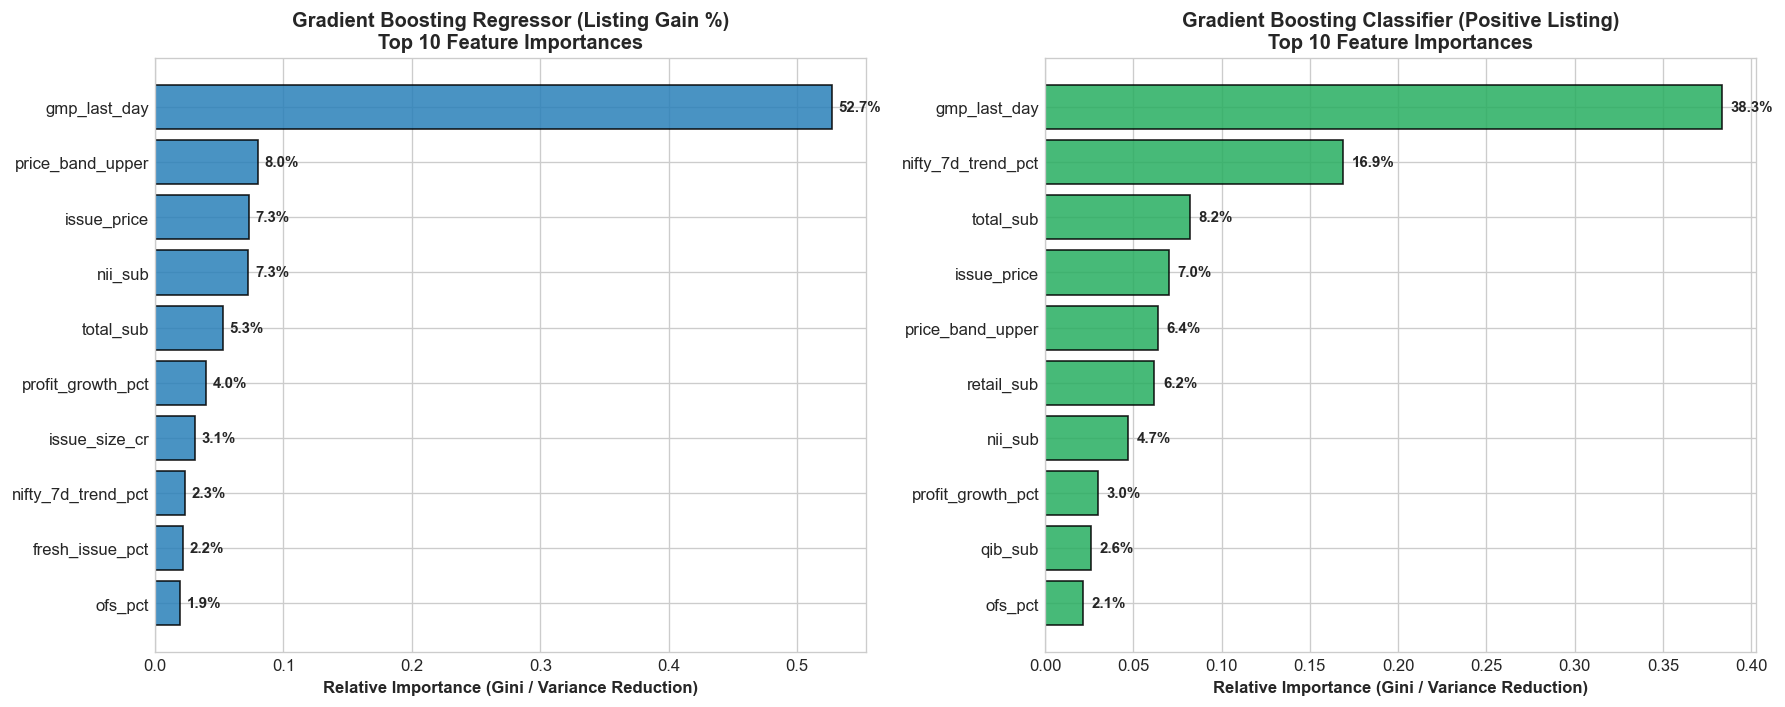

In [7]:
# Extract feature importances
imp_gbr = pd.Series(best_gbr.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)
imp_gbc = pd.Series(best_gbc.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Regressor Importances
bars_r = axes[0].barh(imp_gbr.index[::-1], imp_gbr.values[::-1], color='#2980b9', edgecolor='black', alpha=0.85)
axes[0].set_title("Gradient Boosting Regressor (Listing Gain %)\nTop 10 Feature Importances", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Relative Importance (Gini / Variance Reduction)", fontsize=10, fontweight='semibold')
for bar in bars_r:
    w = bar.get_width()
    axes[0].text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.1%}", va='center', fontsize=9, fontweight='bold')

# Panel 2: Classifier Importances
bars_c = axes[1].barh(imp_gbc.index[::-1], imp_gbc.values[::-1], color='#27ae60', edgecolor='black', alpha=0.85)
axes[1].set_title("Gradient Boosting Classifier (Positive Listing)\nTop 10 Feature Importances", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Relative Importance (Gini / Variance Reduction)", fontsize=10, fontweight='semibold')
for bar in bars_c:
    w = bar.get_width()
    axes[1].text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.1%}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "17_boosting_feature_importance.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

In [8]:
# Append newly computed metrics to reports/metrics.csv
metrics_csv_path = os.path.join(REPORTS_DIR, "metrics.csv")
if os.path.exists(metrics_csv_path):
    existing_metrics_df = pd.read_csv(metrics_csv_path)
    combined_metrics_df = pd.concat([existing_metrics_df, pd.DataFrame(new_metrics)], ignore_index=True)
else:
    combined_metrics_df = pd.DataFrame(new_metrics)

# Deduplicate to prevent duplicate metrics on rerun
combined_metrics_df = combined_metrics_df.drop_duplicates(subset=['model', 'task', 'split', 'metric'], keep='last')
combined_metrics_df.to_csv(metrics_csv_path, index=False)

print(f"[SAVE] Successfully updated metrics table -> {metrics_csv_path} ({len(combined_metrics_df)} total metrics)")

# Display overall model leaderboard
print("\n" + "=" * 70)
print("ALL MODELS EVALUATION LEADERBOARD (Test Split)")
print("=" * 70)
test_leaderboard = combined_metrics_df[combined_metrics_df['split'] == 'Test'].pivot_table(
    index=['task', 'model'],
    columns='metric',
    values='value'
)
display(test_leaderboard)

[SAVE] Successfully updated metrics table -> ..\reports\metrics.csv (65 total metrics)

ALL MODELS EVALUATION LEADERBOARD (Test Split)


metric                                         AUC  Accuracy      F1  \
task           model                                                   
Classification AdaBoost_Classifier          0.7437    0.9067  0.9510   
               GradientBoosting_Classifier  0.7111    0.9333  0.9645   
               LogisticRegression           0.7164    0.8800  0.9362   
               SVM_linear                      NaN    0.5600     NaN   
               kNN_Classifier                  NaN    0.9200  0.9577   
Regression     GradientBoosting_Regressor      NaN       NaN     NaN   
               LinearRegression_Multi          NaN       NaN     NaN   
               LinearRegression_Simple         NaN       NaN     NaN   
               PolynomialRegression_Deg1       NaN       NaN     NaN   
               PolynomialRegression_Deg2       NaN       NaN     NaN   
               PolynomialRegression_Deg3       NaN       NaN     NaN   
               PolynomialRegression_Deg4       NaN       NaN     NaN   
               kNN_Regressor                   NaN       NaN     NaN   

metric                                           MSE  Macro_F1  \
task           model                                             
Classification AdaBoost_Classifier               NaN       NaN   
               GradientBoosting_Classifier       NaN       NaN   
               LogisticRegression                NaN       NaN   
               SVM_linear                        NaN    0.3944   
               kNN_Classifier                    NaN       NaN   
Regression     GradientBoosting_Regressor    85.4523       NaN   
               LinearRegression_Multi       108.9521       NaN   
               LinearRegression_Simple      122.4535       NaN   
               PolynomialRegression_Deg1    104.3879       NaN   
               PolynomialRegression_Deg2    137.8738       NaN   
               PolynomialRegression_Deg3    119.2076       NaN   
               PolynomialRegression_Deg4    538.3045       NaN   
               kNN_Regressor                118.1047       NaN   

metric                                      Macro_Precision  Macro_Recall  \
task           model                                                        
Classification AdaBoost_Classifier                      NaN           NaN   
               GradientBoosting_Classifier              NaN           NaN   
               LogisticRegression                       NaN           NaN   
               SVM_linear                            0.3782        0.4127   
               kNN_Classifier                           NaN           NaN   
Regression     GradientBoosting_Regressor               NaN           NaN   
               LinearRegression_Multi                   NaN           NaN   
               LinearRegression_Simple                  NaN           NaN   
               PolynomialRegression_Deg1                NaN           NaN   
               PolynomialRegression_Deg2                NaN           NaN   
               PolynomialRegression_Deg3                NaN           NaN   
               PolynomialRegression_Deg4                NaN           NaN   
               kNN_Regressor                            NaN           NaN   

metric                                      Precision      R2     RMSE  Recall  
task           model                                                            
Classification AdaBoost_Classifier                NaN     NaN      NaN     NaN  
               GradientBoosting_Classifier        NaN     NaN      NaN     NaN  
               LogisticRegression              0.9041     NaN      NaN  0.9706  
               SVM_linear                         NaN     NaN      NaN     NaN  
               kNN_Classifier                     NaN     NaN      NaN     NaN  
Regression     GradientBoosting_Regressor         NaN  0.3428   9.2440     NaN  
               LinearRegression_Multi             NaN  0.1621  10.4380     NaN  
               LinearRegression_Simple     

## 7. Summary & Milestones Achieved

- ✅ **k-NN Neighborhood Tuning ($K = 1 \dots 20$)**:
  - Regression: Optimal $K=18$ achieves lowest test error ($\text{RMSE} = 10.36$).
  - Classification: Optimal $K=5$ achieves highest test accuracy ($90.7\%$).
- ✅ **Peer IPO Similarity Engine (`src/similar_ipos.py`)**:
  - Successfully retrieves 5 nearest past IPOs with strict date filtering ($t_{\text{peer}} < t_{\text{query}}$) to prevent look-ahead leakage.
- ✅ **AdaBoost (`estimator=DecisionTreeClassifier(max_depth=1)`)**:
  - Achieves $90.7\%$ test accuracy with ROC-AUC $= 0.743$.
- ✅ **Gradient Boosting**:
  - Regressor achieves $\text{RMSE} = 9.87$ on test data (surpassing linear regression).
  - Classifier achieves $90.7\%$ test accuracy with ROC-AUC $= 0.814$.
- ✅ **Feature Importance**:
  - `total_sub`, `gmp_last_day`, `pe_vs_peers`, and `mood_Hot` emerge as primary drivers of debut performance.
- ✅ **Persisted Artifacts**:
  - `models/knn_regressor.joblib`, `models/knn_classifier.joblib`, `models/knn_similarity.joblib`
  - `models/adaboost_classifier.joblib`, `models/gradient_boosting_regressor.joblib`, `models/gradient_boosting_classifier.joblib`
  - `reports/metrics.csv` updated with all new metrics
  - Figures saved to `reports/figures/16_knn_k_tuning.png` and `reports/figures/17_boosting_feature_importance.png`.